# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import pandas as pd

# Load dataset from local environment path
file_path = '/content/hotels (1).csv'
df = pd.read_csv(file_path)

# Display the first few rows
print("--- First 5 Rows of the Dataset ---")
display(df.head())

# Display summary statistics
print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

--- First 5 Rows of the Dataset ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
What stands out to me is that there is a negative value for the Average Daily Rate which doesn't make sense assuming we are paying in dollars. Also, the column company only has 1011 records while most others have the full 9404. One last thing I noticed is the lead time max is 737 days which is a long time and would skew the data.


## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [6]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load dataset from local environment path
file_path = '/content/hotels (1).csv'
df = pd.read_csv(file_path)

# 2.1 Select the specified features
features = ['adr', 'lead_time', 'total_of_special_requests']
prepared_df = df[features].copy()

# 2.2 Clean data: Remove rows where adr is negative
prepared_df = prepared_df[prepared_df['adr'] >= 0]

# Remove duplicate rows
prepared_df = prepared_df.drop_duplicates()

# Remove extreme outliers (e.g., lead_time > 600 or adr > 500 to keep clusters stable)
prepared_df = prepared_df[(prepared_df['lead_time'] <= 600) & (prepared_df['adr'] <= 500)]

# 2.3 Drop any missing values
prepared_df = prepared_df.dropna()

# 2.4 Standardize the features using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(prepared_df)

# Create a DataFrame of the scaled data
scaled_df = pd.DataFrame(scaled_features, columns=features)

print(f"Original dataset shape: {df.shape}")
print(f"Cleaned & scaled dataset shape: {scaled_df.shape}")
print("\n--- Sample of Scaled Data ---")
display(scaled_df.head())

Original dataset shape: (9404, 32)
Cleaned & scaled dataset shape: (6149, 3)

--- Sample of Scaled Data ---


,adr,lead_time,total_of_special_requests
0,-1.782672,3.646834,-0.886179
1,-0.431937,-0.864998,-0.886179
2,-0.431937,-0.784189,-0.886179
3,-0.017712,-0.770721,0.245752
4,0.144376,-0.959275,-0.886179


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. The features I scaled were ADR, lead time and total of special requests. These are important to scale becuase they represent booking behaviors by consumers.
2. What I expect to find using this is last minute bargain hunters with low lead time and only a few special requests. I also wonder what the planners would look like. Maybe they are people and families who booked in advance or request bunk beds for kids.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

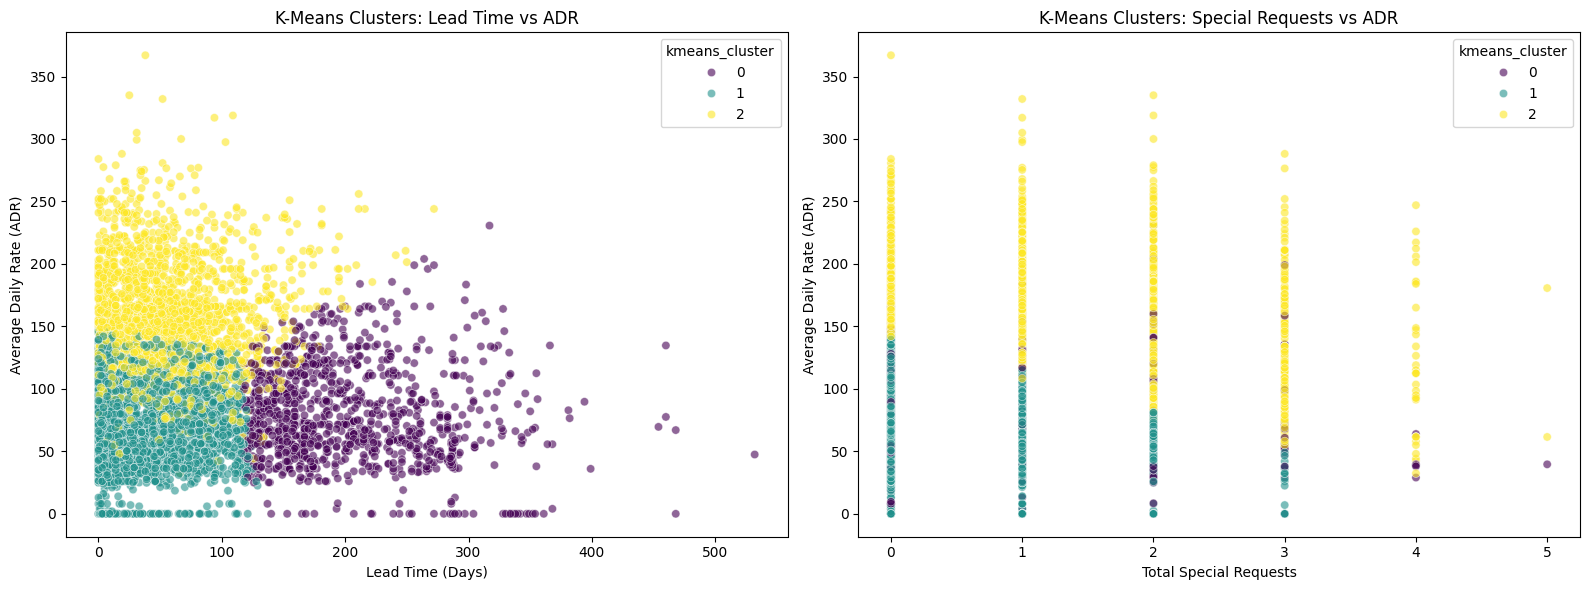


--- K-Means Cluster Averages ---


,adr,lead_time,total_of_special_requests
kmeans_cluster,,,
0,79.064879,203.742468,0.634597
1,67.569547,36.446727,0.521823
2,158.056297,57.258483,1.264970


In [8]:
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

# 3.1 Fit KMeans Model
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
prepared_df['kmeans_cluster'] = kmeans.fit_predict(scaled_df)

# 3.2 Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot 1: Lead Time vs ADR
sns.scatterplot(
    ax=axes[0],
    data=prepared_df,
    x='lead_time',
    y='adr',
    hue='kmeans_cluster',
    palette='viridis',
    alpha=0.6
)
axes[0].set_title('K-Means Clusters: Lead Time vs ADR')
axes[0].set_xlabel('Lead Time (Days)')
axes[0].set_ylabel('Average Daily Rate (ADR)')

# Scatter plot 2: Special Requests vs ADR
sns.scatterplot(
    ax=axes[1],
    data=prepared_df,
    x='total_of_special_requests',
    y='adr',
    hue='kmeans_cluster',
    palette='viridis',
    alpha=0.6
)
axes[1].set_title('K-Means Clusters: Special Requests vs ADR')
axes[1].set_xlabel('Total Special Requests')
axes[1].set_ylabel('Average Daily Rate (ADR)')

plt.tight_layout()
plt.show()

# 3.3 Summary Table
summary_kmeans = prepared_df.groupby('kmeans_cluster')[features].mean()
print("\n--- K-Means Cluster Averages ---")
display(summary_kmeans)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I chose a k value of 3 to establish three distinct customer archetypes (budget/last-minute, long-term planner, and premium spender) making the marketing strategy clean, logical, and highly actionable without overcomplicating segments.

2. Cluster 0 represents guest who plan far in advance. Cluster 1 represents bargain hunters booking on short notice. The final cluster 2 represents people that are high spending and have a high rate of special requests.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

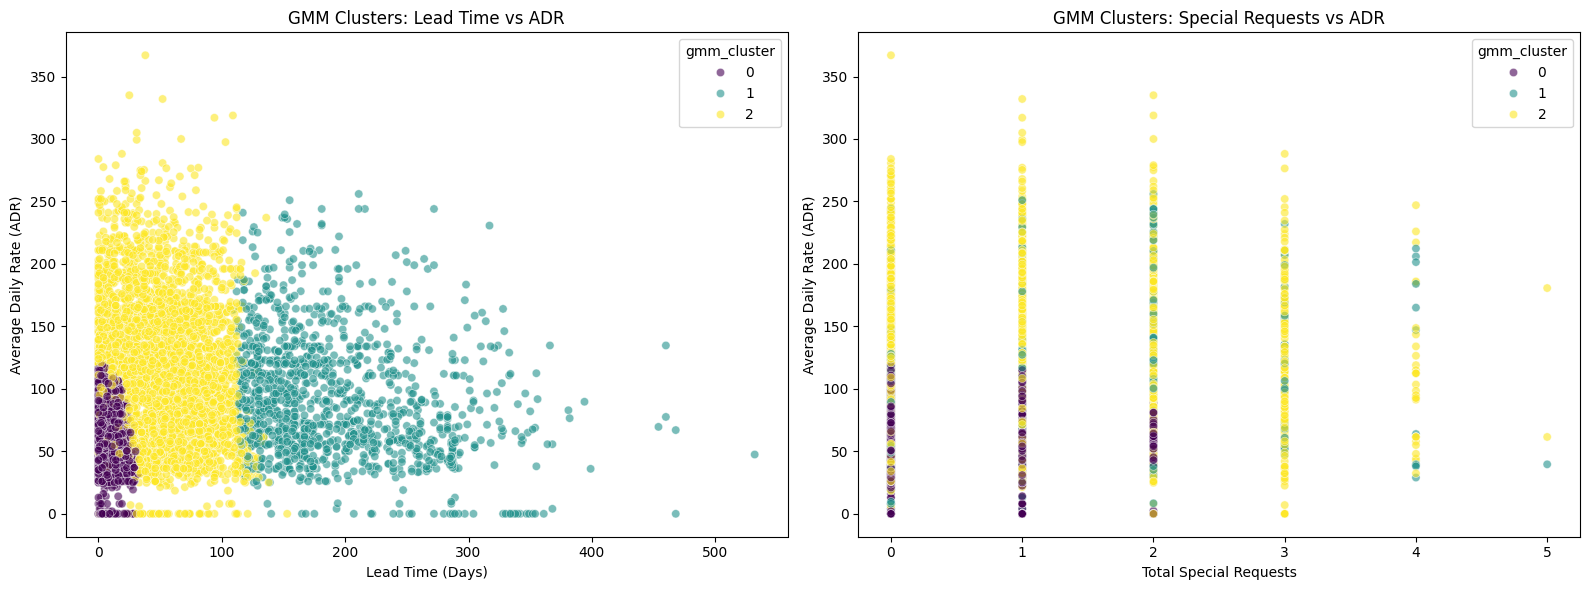


--- GMM Cluster Averages ---


,adr,lead_time,total_of_special_requests
gmm_cluster,,,
0,55.630528,8.331754,0.528097
1,92.484653,192.429482,0.741833
2,120.109675,53.895230,0.908107


In [11]:
from sklearn.mixture import GaussianMixture
import seaborn as sns
import matplotlib.pyplot as plt

# 4.1 Fit GMM Model
k = 3
gmm = GaussianMixture(n_components=k, random_state=42)
prepared_df['gmm_cluster'] = gmm.fit_predict(scaled_df)

# 4.2 Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot 1: Lead Time vs ADR
sns.scatterplot(
    ax=axes[0],
    data=prepared_df,
    x='lead_time',
    y='adr',
    hue='gmm_cluster',
    palette='viridis',
    alpha=0.6
)
axes[0].set_title('GMM Clusters: Lead Time vs ADR')
axes[0].set_xlabel('Lead Time (Days)')
axes[0].set_ylabel('Average Daily Rate (ADR)')

# Scatter plot 2: Special Requests vs ADR
sns.scatterplot(
    ax=axes[1],
    data=prepared_df,
    x='total_of_special_requests',
    y='adr',
    hue='gmm_cluster',
    palette='viridis',
    alpha=0.6
)
axes[1].set_title('GMM Clusters: Special Requests vs ADR')
axes[1].set_xlabel('Total Special Requests')
axes[1].set_ylabel('Average Daily Rate (ADR)')

plt.tight_layout()
plt.show()

# 4.3 Summary Table
summary_gmm = prepared_df.groupby('gmm_cluster')[features].mean()
print("\n--- GMM Cluster Averages ---")
display(summary_gmm)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. In the GMM model, the results weren't as even becuase the clusters were different sizes. The clusters were more overlapped as well and less spread out.

2. The GMM would help target customers better becuase it shows more overlap. Since it shows the overlap between clusters, it could show customers that we could move into the premium category therefor getting them to spend more.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [12]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd

# Calculate metrics for KMeans
wcss_kmeans = kmeans.inertia_
sil_kmeans = silhouette_score(scaled_df, prepared_df['kmeans_cluster'], sample_size=10000, random_state=42)
dbi_kmeans = davies_bouldin_score(scaled_df, prepared_df['kmeans_cluster'])

# Calculate metrics for GMM (WCSS/Inertia is not defined for GMM)
sil_gmm = silhouette_score(scaled_df, prepared_df['gmm_cluster'], sample_size=10000, random_state=42)
dbi_gmm = davies_bouldin_score(scaled_df, prepared_df['gmm_cluster'])

# Create a comparison table
metrics_df = pd.DataFrame({
    'Metric': ['WCSS (Inertia)', 'Silhouette Score (Higher is Better)', 'Davies-Bouldin Index (Lower is Better)'],
    'K-Means': [wcss_kmeans, sil_kmeans, dbi_kmeans],
    'GMM': ['N/A', sil_gmm, dbi_gmm]
})

display(metrics_df)

,Metric,K-Means,GMM
0,WCSS (Inertia),10118.816938,N/A
1,Silhouette Score (Higher is Better),0.315322,0.169081
2,Davies-Bouldin Index (Lower is Better),1.196323,1.548958


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K means performed better when comparing all of the scores. For example, its Silhouette schore is higher which is better.

5.3.  Despite K means performing better, for this particular problem I'd use GMM becuase it shows the clusters overlapping better. Of course for simplicity for people who don't understand how the models work, K means might be a better fit with clearly outlined groups.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [13]:
# 6.1 Display and sort the characteristics of each cluster to make differences clear
print("--- Sorted K-Means Segments (by Average Daily Rate - ADR) ---")
sorted_kmeans = summary_kmeans.sort_values(by='adr', ascending=False)
display(sorted_kmeans)

print("\n--- Sorted GMM Segments (by Average Daily Rate - ADR) ---")
sorted_gmm = summary_gmm.sort_values(by='adr', ascending=False)
display(sorted_gmm)

--- Sorted K-Means Segments (by Average Daily Rate - ADR) ---


,adr,lead_time,total_of_special_requests
kmeans_cluster,,,
2,158.056297,57.258483,1.264970
0,79.064879,203.742468,0.634597
1,67.569547,36.446727,0.521823



--- Sorted GMM Segments (by Average Daily Rate - ADR) ---


,adr,lead_time,total_of_special_requests
gmm_cluster,,,
2,120.109675,53.895230,0.908107
1,92.484653,192.429482,0.741833
0,55.630528,8.331754,0.528097


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Based on the sorted K-Means metrics, the segments represent:
The clustering results identified three main types of hotel guests. High-Value Premium Guests, Cluster 2, spend the most, with an average daily rate of about $158 book around 57 days in advance, and make the most special requests, suggesting they have higher expectations. Early-Bird Planners, Cluster 0, spend a moderate amount of about $79 ADR, book far in advance at around 204 days, and make few special requests. Finally, Last-Minute Value Hunters, Cluster 1, spend the least at about $68 ADR, book closer to their arrival date at around 36 days, and tend to look for basic accommodations.

2. The hotel could tailor promotions for premium guests such as welcome amenities or spa packages to satisfy their higher likelyhood of special requests. For the early bird planners or families, they could offer advance purshase discounts that would make them click purchase. Finally, for the last minute value hunters, they could be targeted with flash sales.
   

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. I think the most challenging was picking variables that may actually correlate. I think I could've picked better variables that would've given more interesting results.

2. I'd use clustering if I wanted to see relationships between different groups of data.

3. I'd say that clusters provide a look into data groupings that can then be targeted for advertizing.

4. For me personally, if I ever owned a wealth management busines, this would help me group customers based on the amount of risk they are willing to take and amount they are willing to invest.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [14]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 1174669 bytes to assignment_09_clustering.html
